In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **Task 1**

In [20]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/adult_income.csv')
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [21]:
print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (48842, 15)
   age         workclass  fnlwgt  education  education-num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital-status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital-gain  capital-loss  hours-per-week native-country income  
0          2174             0              40  United-States  <=50K  
1             0

In [22]:
print("Column name:")
print(df.columns.tolist())
df.info()


Column name:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-coun

1. Pradiction objective- Predict whether a person's income exceeds $50000 per year.

2. Target variable- income

3. Features- Age, education, occupation, working hours, marital status and other demographic/work-related information.

In [23]:
numeric_cols = df.select_dtypes(include=np.number).columns

print(df[numeric_cols].describe().round(2))

            age      fnlwgt  education-num  capital-gain  capital-loss  \
count  48842.00    48842.00       48842.00      48842.00       48842.0   
mean      38.64   189664.13          10.08       1079.07          87.5   
std       13.71   105604.03           2.57       7452.02         403.0   
min       17.00    12285.00           1.00          0.00           0.0   
25%       28.00   117550.50           9.00          0.00           0.0   
50%       37.00   178144.50          10.00          0.00           0.0   
75%       48.00   237642.00          12.00          0.00           0.0   
max       90.00  1490400.00          16.00      99999.00        4356.0   

       hours-per-week  
count        48842.00  
mean            40.42  
std             12.39  
min              1.00  
25%             40.00  
50%             40.00  
75%             45.00  
max             99.00  


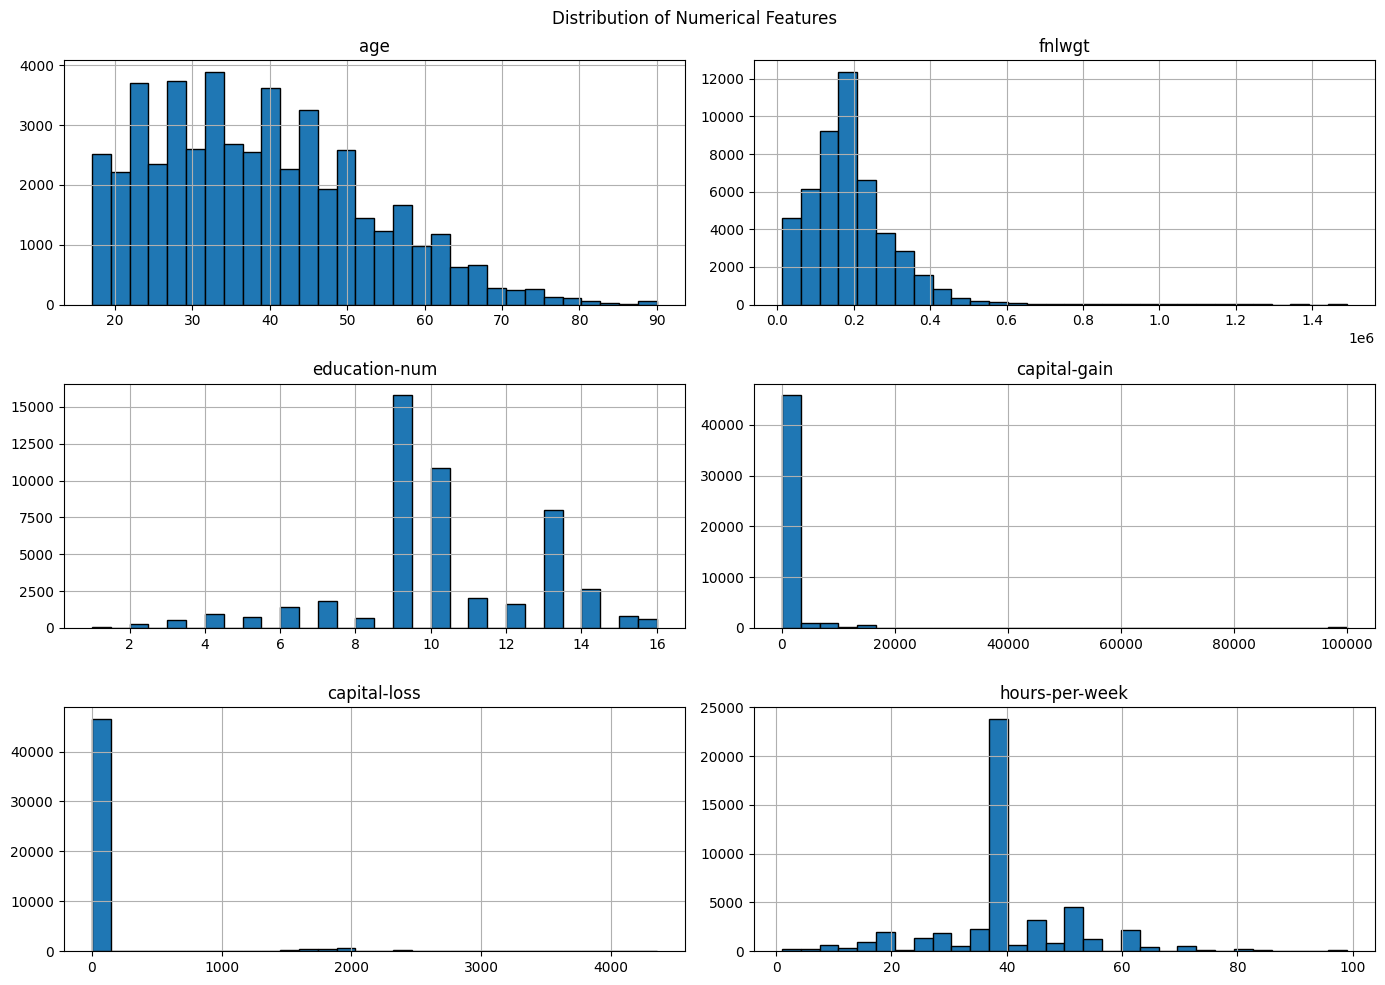

In [24]:
df[numeric_cols].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor='black'
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

In [25]:
categorical_cols = df.select_dtypes(
    include='object'
).columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(10))


workclass:
workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
State-gov            1981
?                    1836
Self-emp-inc         1695
Federal-gov          1432
NaN                   963
Without-pay            21
Never-worked           10
Name: count, dtype: int64

education:
education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters          2657
Assoc-voc        2061
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           955
Prof-school       834
Name: count, dtype: int64

marital-status:
marital-status
Married-civ-spouse       22379
Never-married            16117
Divorced                  6633
Separated                 1530
Widowed                   1518
Married-spouse-absent      628
Married-AF-spouse           37
Name: count, dtype: int64

occupation:
occupation
Prof-specialty       6172
Craft-repair         6112
Exec-managerial      6086
Adm-clerical         5611
Sales                

In [26]:
print(df['income'].value_counts(dropna=False))

income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64


In [27]:
print("Missing values:")
print(df.isnull().sum())

print("\nTotal missing cells:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
income              0
dtype: int64

Total missing cells:
age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
income              0
dtype: int64

Duplicate rows:
29


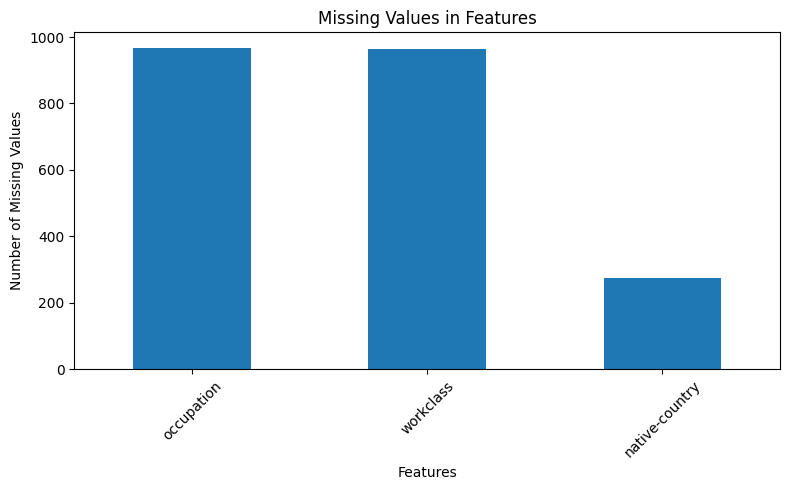

In [28]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(
    ascending=False
)

missing.plot(kind='bar',figsize=(8, 5))

plt.title("Missing Values in Features")
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
question_missing = (
    df.select_dtypes(include='object')
      .apply(lambda col: col.astype('string').str.strip().eq('?').sum())
)

print(question_missing[question_missing > 0])

workclass         1836
occupation        1843
native-country     583
dtype: int64


In [30]:
print("Dataset shape:", df.shape)

print("\nMissing values (NaN):")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nTarget distribution:")
print(df['income'].value_counts())

Dataset shape: (48842, 15)

Missing values (NaN):
age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
income              0
dtype: int64

Duplicate rows:
29

Target distribution:
income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64


## **Task 2**

In [31]:
df_original = df.copy(deep=True)

df_clean = df_original.copy(deep=True)

print("Original shape:", df_original.shape)
print("Working copy shape:", df_clean.shape)

Original shape: (48842, 15)
Working copy shape: (48842, 15)


In [32]:
df_clean = df_clean.replace(
    r'^\s*\?\s*$',
    np.nan,
    regex=True
)

print("Missing values after standardization:")
print(df_clean.isnull().sum())

Missing values after standardization:
age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
income               0
dtype: int64


In [33]:
df_clean['income'] = (
    df_clean['income']
    .astype('string')
    .str.strip()
    .str.replace(r'\.$', '', regex=True)
)

print(df_clean['income'].value_counts(dropna=False))

income
<=50K    37155
>50K     11687
Name: count, dtype: Int64


In [34]:
duplicate_count = df_clean.duplicated().sum()

print("Duplicate rows found:", duplicate_count)

df_clean = df_clean.drop_duplicates().copy()

print("Shape after removing duplicates:", df_clean.shape)

Duplicate rows found: 52
Shape after removing duplicates: (48790, 15)


In [35]:
cat_cols = df_clean.select_dtypes(
    include=['object', 'string']
).columns

for col in cat_cols:
    df_clean[col] = df_clean[col].str.strip()

print("Category whitespace standardization completed.")

Category whitespace standardization completed.


In [36]:
print("Original dataset shape:", df_original.shape)
print("Cleaned working dataset shape:", df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

print("\nRemaining duplicates:", df_clean.duplicated().sum())

print("\nIncome categories:")
print(df_clean['income'].value_counts(dropna=False))

Original dataset shape: (48842, 15)
Cleaned working dataset shape: (48790, 15)

Remaining missing values:
age                  0
workclass         2795
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2805
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     856
income               0
dtype: int64

Remaining duplicates: 0

Income categories:
income
<=50K    37109
>50K     11681
Name: count, dtype: Int64


In [40]:
numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns

print("Negative values:")
print((df_clean[numeric_cols] < 0).sum())

print("\nNumerical summary:")
print(df_clean[numeric_cols].describe().round(2))

Negative values:
age               0
fnlwgt            0
education-num     0
capital-gain      0
capital-loss      0
hours-per-week    0
dtype: int64

Numerical summary:
            age      fnlwgt  education-num  capital-gain  capital-loss  \
count  48790.00    48790.00       48790.00      48790.00      48790.00   
mean      38.65   189669.00          10.08       1080.22         87.60   
std       13.71   105617.23           2.57       7455.91        403.21   
min       17.00    12285.00           1.00          0.00          0.00   
25%       28.00   117555.00           9.00          0.00          0.00   
50%       37.00   178138.50          10.00          0.00          0.00   
75%       48.00   237606.25          12.00          0.00          0.00   
max       90.00  1490400.00          16.00      99999.00       4356.00   

       hours-per-week  
count        48790.00  
mean            40.43  
std             12.39  
min              1.00  
25%             40.00  
50%             40.

In [38]:
cleaning_summary = pd.DataFrame({
    "Original Missing Values": df_original.isnull().sum(),
    "Cleaned Missing Values": df_clean.isnull().sum(),
    "Original Duplicates": [
        df_original.duplicated().sum()
    ] * len(df_original.columns)
})

print(cleaning_summary)

                Original Missing Values  Cleaned Missing Values  \
age                                   0                       0   
workclass                           963                    2795   
fnlwgt                                0                       0   
education                             0                       0   
education-num                         0                       0   
marital-status                        0                       0   
occupation                          966                    2805   
relationship                          0                       0   
race                                  0                       0   
sex                                   0                       0   
capital-gain                          0                       0   
capital-loss                          0                       0   
hours-per-week                        0                       0   
native-country                      274                     85

## **Task 3**

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Use one numerical column for demonstration
sample = df_clean[['age']].dropna()

standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

standard_values = standard_scaler.fit_transform(sample)
minmax_values = minmax_scaler.fit_transform(sample)

comparison = pd.DataFrame({
    "Original age": sample["age"].values[:10],
    "StandardScaler": standard_values[:10, 0],
    "MinMaxScaler": minmax_values[:10, 0]
})

print(comparison.round(3))

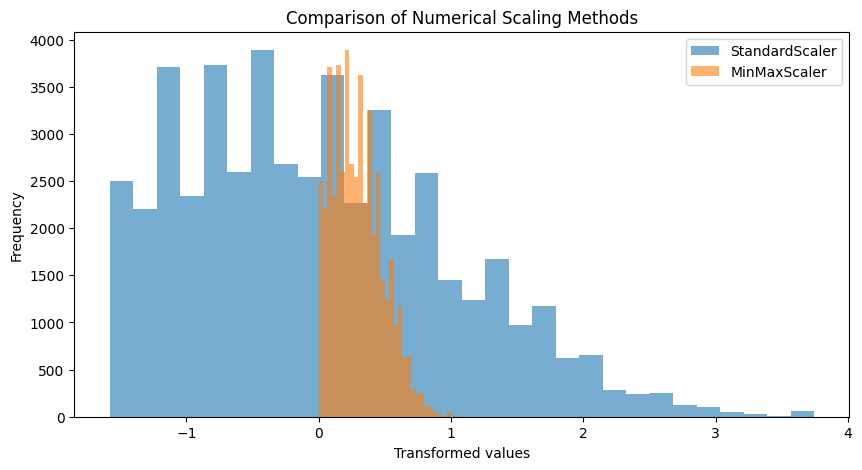

In [43]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Ensure scaled values are defined locally in case the previous cell wasn't run
sample = df_clean[['age']].dropna()

standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

standard_values = standard_scaler.fit_transform(sample)
minmax_values = minmax_scaler.fit_transform(sample)

plt.figure(figsize=(10, 5))

plt.hist(standard_values, bins=30, alpha=0.6, label="StandardScaler")
plt.hist(minmax_values, bins=30, alpha=0.6, label="MinMaxScaler")

plt.title("Comparison of Numerical Scaling Methods")
plt.xlabel("Transformed values")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [45]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

sample_cat = df_clean[['sex']].dropna()

encoded = encoder.fit_transform(sample_cat)

encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(['sex'])
)

print(encoded_df.head())

   sex_Female  sex_Male
0         0.0       1.0
1         0.0       1.0
2         0.0       1.0
3         0.0       1.0
4         1.0       0.0


## **Task 4**

In [ ]:
from sklearn.model_selection import train_test_split


X = df_clean.drop(columns=['income'])
y = df_clean['income'].str.strip()


print(y.value_counts(dropna=False))

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'string']
).columns.tolist()


baseline_preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

baseline_model = Pipeline([
    ('preprocessing', baseline_preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])


improved_preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

improved_model = Pipeline([
    ('preprocessing', improved_preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

print("Both pipelines created successfully.")

In [ ]:
baseline_model.fit(X_train, y_train)
improved_model.fit(X_train, y_train)

print("Baseline training completed.")
print("Improved model training completed.")

## **Task 5**

In [47]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import numpy as np


X = df_clean.drop(columns=['income'])
y = df_clean['income'].str.strip()

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'string']).columns.tolist()


improved_preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

leaky_preprocessor = clone(improved_preprocessor)
X_leaky = leaky_preprocessor.fit_transform(X)

X_train_leaky, X_test_leaky, y_train_leaky, y_test_leaky = (
    train_test_split(
        X_leaky,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

leaky_classifier = LogisticRegression(max_iter=1000)
leaky_classifier.fit(X_train_leaky, y_train_leaky)

leaky_predictions = leaky_classifier.predict(X_test_leaky)

print(
    "Flawed demonstration accuracy:",
    round(accuracy_score(y_test_leaky, leaky_predictions), 4)
)

Flawed demonstration accuracy: 0.8521


## **Task 6**

In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd


X = df_clean.drop(columns=['income'])
y = df_clean['income'].str.strip()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object', 'string']).columns.tolist()


baseline_preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

baseline_model = Pipeline([
    ('preprocessing', baseline_preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])


improved_preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

improved_model = Pipeline([
    ('preprocessing', improved_preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])


baseline_model.fit(X_train, y_train)
improved_model.fit(X_train, y_train)


models = {
    "Baseline": baseline_model,
    "Improved": improved_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)

    positive_index = list(model.classes_).index('>50K')

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            pos_label='>50K', zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            pos_label='>50K', zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions,
            pos_label='>50K', zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == '>50K').astype(int),
            probabilities[:, positive_index]
        )
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


      Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
0  Baseline    0.8498     0.7309  0.5895    0.6526   0.8874
1  Improved    0.8520     0.7304  0.6053    0.6620   0.9081


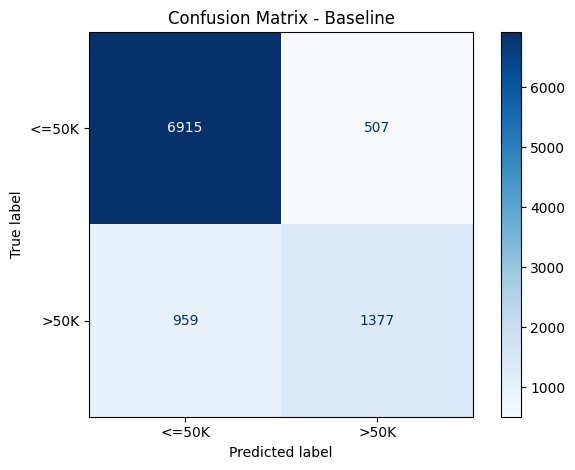

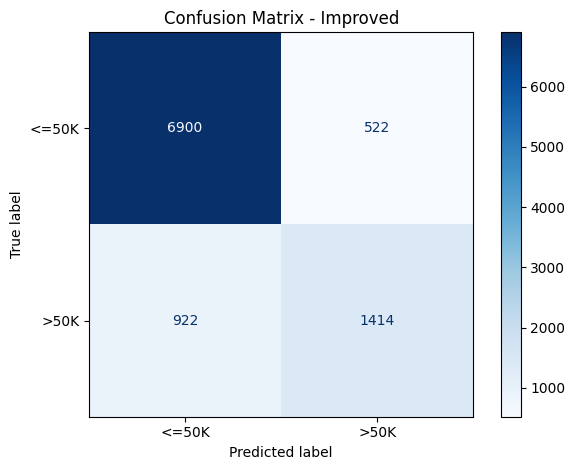

In [51]:
for name, model in models.items():
    predictions = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=['<=50K', '>50K'],
        cmap='Blues',
        values_format='d'
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

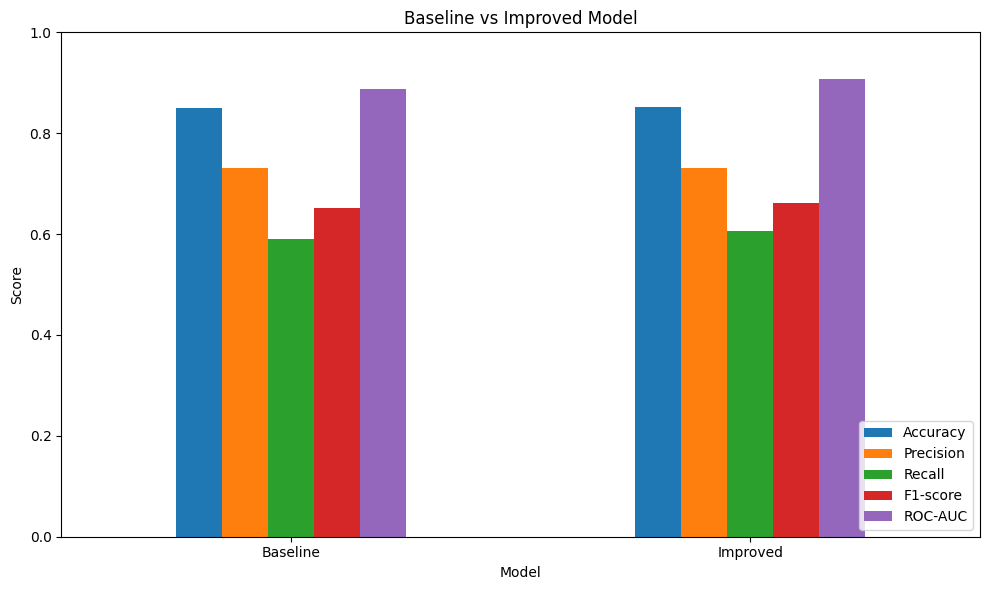

In [52]:
results_df.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']
].plot(kind='bar', figsize=(10, 6))

plt.title("Baseline vs Improved Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [53]:
import sklearn
import sys

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("\nRandom seed: 42")
print("Test size: 20%")
print("Split strategy: Stratified train/test split")
print("Classifier: Logistic Regression")
print("Original dataset rows:", len(df_original))
print("Original dataset columns:", len(df_original.columns))
print("Cleaned dataset rows:", len(df_clean))
print("Cleaned dataset columns:", len(df_clean.columns))

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Pandas version: 2.2.3
NumPy version: 2.1.3
Scikit-learn version: 1.6.1

Random seed: 42
Test size: 20%
Split strategy: Stratified train/test split
Classifier: Logistic Regression
Original dataset rows: 48842
Original dataset columns: 15
Cleaned dataset rows: 48790
Cleaned dataset columns: 15


In [54]:
df_clean.to_csv(
    'adult_income_cleaned.csv',
    index=False
)

results_df.to_csv(
    'model_comparison.csv',
    index=False
)

print("Cleaned dataset and model comparison saved.")

Cleaned dataset and model comparison saved.


In [55]:
from google.colab import files

files.download('adult_income_cleaned.csv')
files.download('model_comparison.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>